<a href="https://colab.research.google.com/github/vusu4242/hm2_vus_konovalenko/blob/main/notebooks/00_eda_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os
from google.colab import userdata
token = userdata.get('hm2')
os.environ["KAGGLE_API_TOKEN"] = token

In [11]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content/data
!cd /content/data && unzip -q '*.zip' && rm *.zip
!ls /content/data

100% 9.88G/9.88G [01:52<00:00, 94.2MB/s]

test  test_images.csv  train  val


Структура папок

In [12]:
from pathlib import Path
ROOT = Path('/content/data')

for split in ['train', 'val']:
    d = ROOT / split
    clips = sorted(p.name for p in (d / 'images').iterdir())
    n_img = sum(1 for _ in (d / 'images').rglob('*.jpg'))
    n_ign = sum(1 for _ in (d / 'ignore').rglob('*.txt')) if (d / 'ignore').exists() else 0
    print(f'{split}: {len(clips)} кліпів, {n_img} кадрів, {n_ign} кадрів з ignore; приклад кліпів: {clips[:3]}')

n_test = sum(1 for _ in (ROOT / 'test/images').rglob('*.jpg'))
print(f'test: {n_test} кадрів')
print(open(ROOT / 'train/data.yaml').read())

train: 56 кліпів, 24201 кадрів, 18090 кадрів з ignore; приклад кліпів: ['uav0000013_00000_v', 'uav0000013_01073_v', 'uav0000013_01392_v']
val: 7 кліпів, 2846 кадрів, 1434 кадрів з ignore; приклад кліпів: ['uav0000086_00000_v', 'uav0000117_02622_v', 'uav0000137_00458_v']
test: 3811 кадрів
path: .
train: images
val: images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



COCO-анотації в pandas:

In [13]:
import json, numpy as np, pandas as pd

def load(split):
    coco = json.load(open(ROOT / split / 'annotations_coco.json'))
    imgs = pd.DataFrame(coco['images']).rename(columns={'id': 'image_id'})
    # назва кліпу: колонка 'video', або папка з file_name
    if 'video' not in imgs.columns:
        imgs['video'] = imgs['file_name'].map(lambda p: Path(p).parent.name)
    anns = pd.DataFrame(coco['annotations'])
    anns[['x', 'y', 'w', 'h']] = pd.DataFrame(anns['bbox'].tolist(), index=anns.index)
    anns['cls'] = anns['category_id'] - 1            # 0-based, як у YOLO і сабміті
    if 'iscrowd' not in anns.columns:
        anns['iscrowd'] = 0
    anns = anns.merge(imgs[['image_id', 'video', 'width', 'height']], on='image_id')
    anns['split'] = split
    imgs['split'] = split
    return coco, imgs, anns

coco_tr, imgs_tr, anns_tr = load('train')
coco_va, imgs_va, anns_va = load('val')

print(coco_tr['categories'])
print('\nКолонки images:', list(imgs_tr.columns))
print(imgs_tr.head(3))
print('\nКолонки annotations:', list(anns_tr.columns))
print(anns_tr.head(3))

[{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]

Колонки images: ['image_id', 'file_name', 'width', 'height', 'video_id', 'video', 'frame_id', 'split']
   image_id                              file_name  width  height  video_id  \
0         1  images/uav0000013_00000_v/0000001.jpg   1344     756         1   
1         2  images/uav0000013_00000_v/0000002.jpg   1344     756         1   
2         3  images/uav0000013_00000_v/0000003.jpg   1344     756         1   

                video  frame_id  split  
0  uav0000013_00000_v         1  train  
1  uav0000013_00000_v         2  train  
2  uav0000013_00000_v         3  train  

Колонки annotations: ['id', 'image_id', 'category_id', 'bbox', 'area', 'iscrowd', 'truncation', 'occlusion', 'track_id', 'orig_category_id', 'ignore', 'x', 'y', 'w', 'h', 'cls', 'video', 'w

Class distribution

In [14]:
CLASSES = ['person','bicycle','car','van','truck','tricycle','bus','motor']
anns = pd.concat([anns_tr, anns_va], ignore_index=True)
imgs = pd.concat([imgs_tr, imgs_va], ignore_index=True)
obj = anns[anns['iscrowd'] == 0]      # цільові об'єкти
ign = anns[anns['iscrowd'] == 1]      # ignored regions

print("Об'єктів:", obj.groupby('split').size().to_dict())
print('Ignored regions:', ign.groupby('split').size().to_dict())

# розподіл класів, % від усіх об'єктів у спліті
dist = obj.groupby(['cls', 'split']).size().unstack('split').fillna(0)
dist.index = [CLASSES[int(i)] for i in dist.index]
print('\nКласи, %:\n', (dist / dist.sum() * 100).round(1))

# розміри кадрів
print('\nРозміри кадрів:\n', imgs.groupby(['split', 'width', 'height']).size())

Об'єктів: {'train': 1105516, 'val': 114132}
Ignored regions: {'train': 510744, 'val': 31960}

Класи, %:
 split     train   val
person     29.7  44.1
bicycle     3.6   5.3
car        45.7  27.9
van         4.2   6.0
truck       2.8   1.2
tricycle    3.7   4.8
bus         0.9   0.2
motor       9.3  10.5

Розміри кадрів:
 split  width  height
train  1344   756        5645
       1360   765         962
       1904   1071      12895
       1920   1080        721
       2688   1512       3505
       2720   1530        473
val    1344   756         827
       1904   1071        459
       2688   1512        233
       2720   1530        349
       3840   2160        978
dtype: int64


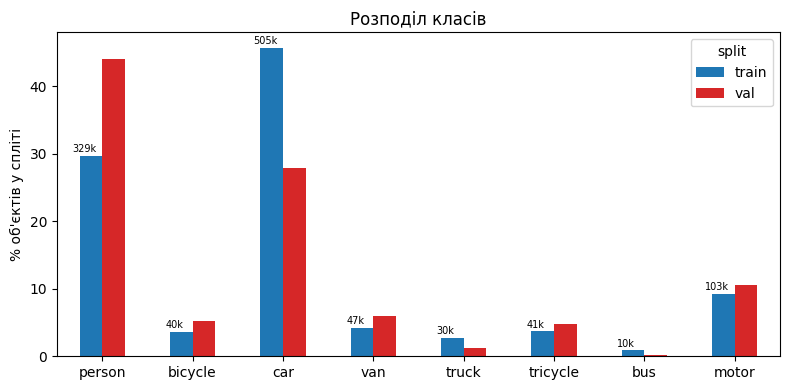

In [21]:
cnt = obj.groupby(['cls', 'split']).size().unstack()
cnt.index = CLASSES
pct = cnt / cnt.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
pct.plot(kind='bar', ax=ax, color=['tab:blue', 'tab:red'])
for i, v in enumerate(cnt['train']):
    ax.text(i - .2, pct['train'].iloc[i] + .5, f'{v/1000:.0f}k', ha='center', fontsize=7)
ax.set_ylabel('% об\'єктів у спліті'); ax.set_title('Розподіл класів')
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('cls_overall.png', dpi=120); plt.show()

Висновок по **class distribution**:

1. Які класи домінують - **car**(45.7%), **person**(29.7%) - всього майже 75% всіх об`єктів.
2. Рідкісні класи - **bus**(0.9%), **truck**(2.8%), **bicycle**(3.6%), **tricycle**(3.7%), **van**(4.2%).
Різниця між найчастішим і найрідкіснішим класом майже в 50 разів -> дані сильно незбалансовані.
3. У train і val не пропорційно тих самих об`єктів(person - 29.7 vs 44.1) .

### Distribution of object sizes

### Number of objects per frame

### Describe how these vary across sequences

In [16]:
import matplotlib.pyplot as plt, seaborn as sns

# частка кожного класу в кожному кліпі
comp = obj.groupby(['video', 'cls']).size().unstack(fill_value=0)
comp.columns = CLASSES
comp_pct = comp.div(comp.sum(1), axis=0) * 100
split_of = imgs.drop_duplicates('video').set_index('video')['split']

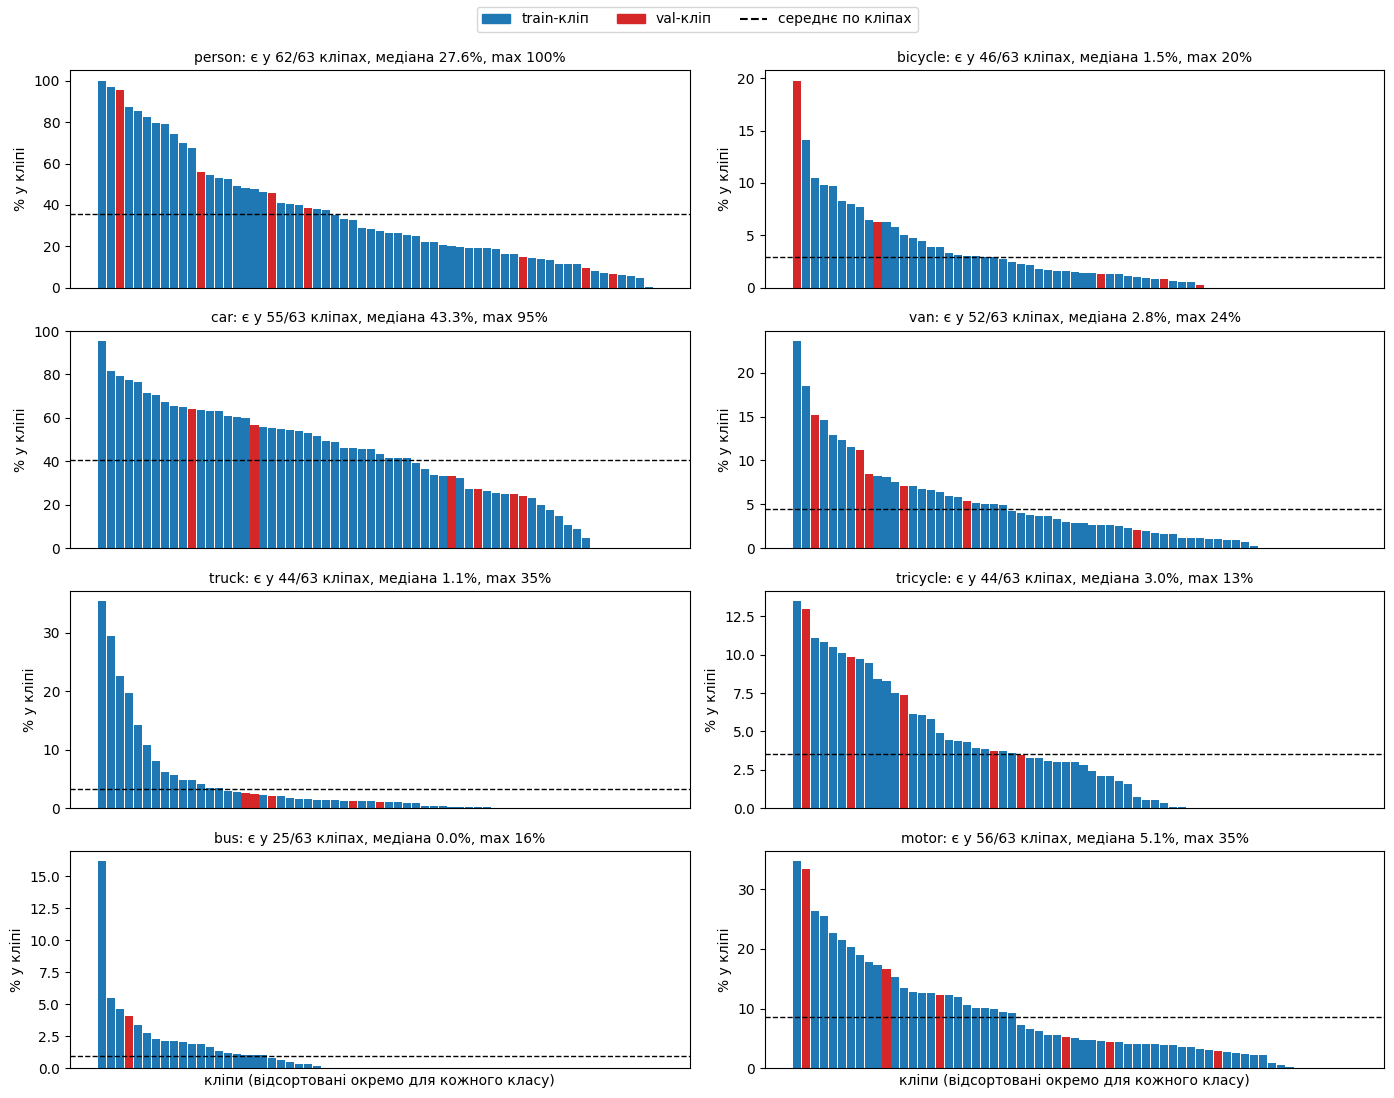

In [20]:
import matplotlib.pyplot as plt

# частка кожного класу в кожному кліпі, %
comp = obj.groupby(['video', 'cls']).size().unstack(fill_value=0)
comp.columns = CLASSES
comp_pct = comp.div(comp.sum(1), axis=0) * 100
split_of = imgs.drop_duplicates('video').set_index('video')['split']

fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for ax, c in zip(axes.flat, CLASSES):
    s = comp_pct[c].sort_values(ascending=False)        # кліпи від найбільшої частки до найменшої
    colors = ['tab:red' if split_of[v] == 'val' else 'tab:blue' for v in s.index]
    ax.bar(range(len(s)), s.values, color=colors, width=.9)
    ax.axhline(s.mean(), c='k', ls='--', lw=1)
    ax.set_title(f'{c}: є у {(s > 0).sum()}/{len(s)} кліпах, '
                 f'медіана {s.median():.1f}%, max {s.max():.0f}%', fontsize=10)
    ax.set_ylabel('% у кліпі')
for ax in axes[-1]:
    ax.set_xlabel('кліпи (відсортовані окремо для кожного класу)')
    ax.set_xticks([])
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='tab:blue'), plt.Rectangle((0, 0), 1, 1, color='tab:red'),
                    plt.Line2D([], [], c='k', ls='--')],
           labels=['train-кліп', 'val-кліп', 'середнє по кліпах'], loc='upper center', ncol=3)
plt.tight_layout(rect=[0, 0, 1, .97]); plt.savefig('cls_per_clip.png', dpi=120); plt.show()